<a href="https://colab.research.google.com/github/karquiza/bikeshare-toronto-demand/blob/main/notebooks/00_init_explore.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAI 103 Group Assignment 1 – Milestone 3 (EDA)
## Notebook 00: Initial Exploration of the Raw Trip Files

#### Objective
- First look at the dataset (no cleaning yet, just observe)
- Check the size, columns, data types, missing values, duplicates and strange values on a few sample months first, then confirm the same checks on all 39 months (Jan 2023 to Mar 2026).
- The proposed cleaning rules are listed at the end.
- Nothing is dropped, renamed or recoded in the data files in this notebook.

## 0. Setup

In [1]:
# Import libraries
import os, glob, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

The raw files live in `data/raw/<year>/`. On Colab this is the shared Google Drive folder; on a laptop it is the `data` folder next to the repo's `notebooks` folder.

In [2]:
# Where the data is (works in Colab and on a laptop)
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA = "/content/drive/MyDrive/DataSets"    # shared Drive folder
else:
    DATA = "../data"

RAW = f"{DATA}/raw"
PROFILE = f"{DATA}/profile"          # small output tables from this notebook go here
os.makedirs(PROFILE, exist_ok=True)
print("Raw data folder:", RAW)

Mounted at /content/drive
Raw data folder: /content/drive/MyDrive/DataSets/raw


In [3]:
# Get the size of the full dataset. The year and month come from the file name (e.g. "2023-01", "2024-01_Jan", "2025_01")
files = sorted(glob.glob(f"{RAW}/*/*.csv"))

file_table = []
for f in files:
    m = re.search(r"(20\d\d)[-_](\d\d)", os.path.basename(f))
    file_table.append({"year": int(m.group(1)), "month": int(m.group(2)),
                       "file": os.path.basename(f), "size_MB": round(os.path.getsize(f) / 1e6, 1)})
file_table = pd.DataFrame(file_table).sort_values(["year", "month"]).reset_index(drop=True)

print("Number of monthly files:", len(file_table))
print("Total size (MB):", file_table["size_MB"].sum().round(1))
print(file_table.groupby("year").agg(months=("month", "count"), size_MB=("size_MB", "sum")))

Number of monthly files: 39
Total size (MB): 2840.0
      months  size_MB
year                 
2023      12    729.9
2024      12    962.1
2025      12   1071.2
2026       3     76.8


## 1. First Look: One Month per Year

Loading all 39 files at once would need more memory than Colab has, so we start with one month per year (January) plus one busy summer month (July 2024). This is enough to see how the files differ between years.

### 1.1 Load the sample months

In [4]:
# Read one January per year, plus July 2024, with plain pd.read_csv (no cleaning yet)
sample_paths = {
    "2023-01": f"{RAW}/2023/Bike share ridership 2023-01.csv",
    "2024-01": f"{RAW}/2024/bikeshare-ridership-2024-01_Jan.csv",
    "2024-07": f"{RAW}/2024/bikeshare-ridership-2024-07_Jul.csv",
    "2025-01": f"{RAW}/2025/bikeshare_2025_01.csv",
    "2026-01": f"{RAW}/2026/bikeshare_2026_01.csv",
}
samples = {name: pd.read_csv(path, low_memory=False) for name, path in sample_paths.items()}
for name, df in samples.items():
    print(name, "loaded:", df.shape)

2023-01 loaded: (180135, 10)
2024-01 loaded: (204879, 11)
2024-07 loaded: (906372, 11)
2025-01 loaded: (202946, 11)
2026-01 loaded: (137336, 11)


### 1.2 Check structure and types

In [5]:
# Get the size, duplicates, data types and null counts for each sample month
for name, df in samples.items():
    print(f"\n==================== {name} ====================")
    print("SIZE (rows, columns): ", df.shape)
    print("No. of Duplicate Rows:", df.duplicated().sum())
    print("\n------------DATA TYPES-------------")
    print(df.dtypes)
    print("\n------------MISSING VALUES-------------")
    print(df.isna().sum())


==================== 2023-01 ====================
SIZE (rows, columns):  (180135, 10)
No. of Duplicate Rows: 0

------------DATA TYPES-------------
Trip Id                 int64
Trip  Duration          int64
Start Station Id        int64
Start Time             object
Start Station Name     object
End Station Id        float64
End Time               object
End Station Name       object
Bike Id                 int64
User Type              object
dtype: object

------------MISSING VALUES-------------
Trip Id                   0
Trip  Duration            0
Start Station Id          0
Start Time                0
Start Station Name    10630
End Station Id          103
End Time                  0
End Station Name      10808
Bike Id                   0
User Type                 0
dtype: int64

==================== 2024-01 ====================
SIZE (rows, columns):  (204879, 11)
No. of Duplicate Rows: 0

------------DATA TYPES-------------
Trip_Id                 int64
Trip_Duration           

**OBSERVATIONS:**
- Size: the sample months have between 137,336 (Jan 2026) and 906,372 (Jul 2024) trips. Summer months are 4 to 5 times bigger than winter months.
- No fully duplicated rows in any of the sample months.
- The 2023 file has 10 columns and the later files have 11: `Bike_Model` only exists from 2024. The 2023 column names are also written differently (spaces instead of underscores). This is fixed in 1.3.
- Data types: `Start Time` / `End Time` are read as strings (object) and need to be converted to dates. `End Station Id` is read as a decimal number (float) because the column has missing values, so the ids look like `7130.0`. We need to be careful with this because this is and identifier and not a number. We may need to convert this when merging with the weather data.
- Missing values: 2023 has many missing station **names** (10,630 `Start Station Name` in Jan 2023) but no missing station **ids**. `End_Station_Id` is missing in every month (89 to 1,743 rows per sample month). From 2024, `End_Time` is also missing in a few rows (4 to 2,170).

### 1.3 Compare the column names across years

In [6]:
# Put the column names of each year side by side
cols = pd.DataFrame({name: pd.Series(list(df.columns)) for name, df in samples.items()})
cols

,2023-01,2024-01,2024-07,2025-01,2026-01
0,Trip Id,Trip_Id,Trip_Id,Trip_Id,Trip_Id
1,Trip Duration,Trip_Duration,Trip_Duration,Trip_Duration,Trip_Duration
2,Start Station Id,Start_Station_Id,Start_Station_Id,Start_Station_Id,Start_Station_Id
3,Start Time,Start_Time,Start_Time,Start_Time,Start_Time
4,Start Station Name,Start_Station_Name,Start_Station_Name,Start_Station_Name,Start_Station_Name
5,End Station Id,End_Station_Id,End_Station_Id,End_Station_Id,End_Station_Id
6,End Time,End_Time,End_Time,End_Time,End_Time
7,End Station Name,End_Station_Name,End_Station_Name,End_Station_Name,End_Station_Name
8,Bike Id,Bike_Id,Bike_Id,Bike_Id,Bike_Id
9,User Type,User_Type,User_Type,User_Type,User_Type


In [7]:
# The 2023 column names use spaces ("Trip  Duration" even has two spaces) and the first one carries a BOM character.
# From 2024 the names use underscores and there is an extra column Bike_Model.
# This is the mapping from the 2023 names to the standard (2024+) names that the group will use from here on.
RENAME_2023 = {
    "Trip Id": "Trip_Id",
    "Trip  Duration": "Trip_Duration",
    "Start Station Id": "Start_Station_Id",
    "Start Time": "Start_Time",
    "Start Station Name": "Start_Station_Name",
    "End Station Id": "End_Station_Id",
    "End Time": "End_Time",
    "End Station Name": "End_Station_Name",
    "Bike Id": "Bike_Id",
    "User Type": "User_Type",
}
STANDARD_COLUMNS = ["Trip_Id", "Trip_Duration", "Start_Station_Id", "Start_Time", "Start_Station_Name",
                    "End_Station_Id", "End_Time", "End_Station_Name", "Bike_Id", "User_Type", "Bike_Model"]

def standardize_columns(df):
    """Give every year's file the same column names. Adds an empty Bike_Model for 2023. No rows are changed."""
    df = df.copy()
    df.columns = [c.replace("\ufeff", "") for c in df.columns]   # remove the BOM character
    df = df.rename(columns=RENAME_2023)
    if "Bike_Model" not in df.columns:
        df["Bike_Model"] = np.nan
    return df[STANDARD_COLUMNS]

# Apply to the samples and confirm the columns now match
for name in samples:
    samples[name] = standardize_columns(samples[name])
print("All sample months now have identical columns:",
      all(list(df.columns) == STANDARD_COLUMNS for df in samples.values()))

All sample months now have identical columns: True


### 1.4 Compare how the same field is written in each year

In [8]:
# Date format, user type labels, bike models, and how the station id is stored
for name, df in samples.items():
    print(f"\n==================== {name} ====================")
    print("Start_Time example:      ", df["Start_Time"].iloc[0])
    print("End_Station_Id dtype:    ", df["End_Station_Id"].dtype, "  example:", df["End_Station_Id"].iloc[0])
    print("User_Type values:        ", df["User_Type"].value_counts(dropna=False).to_dict())
    print("Bike_Model values:       ", df["Bike_Model"].value_counts(dropna=False).to_dict())


==================== 2023-01 ====================
Start_Time example:       01/01/2023 00:00
End_Station_Id dtype:     float64   example: 7703.0
User_Type values:         {'Casual Member': 130135, 'Annual Member': 50000}
Bike_Model values:        {nan: 180135}

==================== 2024-01 ====================
Start_Time example:       2024-01-01 00:00:08
End_Station_Id dtype:     float64   example: 7130.0
User_Type values:         {'Member': 190402, 'Casual': 14477}
Bike_Model values:        {'ICONIC': 195391, 'EFIT G5': 6634, 'EFIT': 2854}

==================== 2024-07 ====================
Start_Time example:       2024-07-01 00:00:05
End_Station_Id dtype:     float64   example: 7718.0
User_Type values:         {'Member': 641196, 'Casual': 265176}
Bike_Model values:        {'ICONIC': 760874, 'EFIT G5': 96547, 'EFIT': 48951}

==================== 2025-01 ====================
Start_Time example:       2025-01-01 00:02:15
End_Station_Id dtype:     float64   example: 7155.0
User_Type va

The 2023 dates look like `01/01/2023 00:00`. That could be day/month or month/day. Checking which position ever goes above 12 settles it:

In [9]:
# In 2023, is the date month/day or day/month? Look at which of the first two numbers goes above 12.
st = samples["2023-01"]["Start_Time"]
first  = st.str.slice(0, 2).astype(int)
second = st.str.slice(3, 5).astype(int)
print("Rows where the FIRST number is above 12: ", (first > 12).sum())
print("Rows where the SECOND number is above 12:", (second > 12).sum())
print("Last rows of the January file:", st.tail(2).tolist())

Rows where the FIRST number is above 12:  0
Rows where the SECOND number is above 12: 106796
Last rows of the January file: ['01/31/2023 23:57', '01/31/2023 23:59']


In [10]:
# Date format used by each schema (used from here on)
DATE_FORMAT = {"2023": "%m/%d/%Y %H:%M", "2024+": "%Y-%m-%d %H:%M:%S"}

def parse_times(df):
    """Parse Start_Time and End_Time using the format of the year. Unparseable values become NaT (not a time)."""
    df = df.copy()
    fmt = DATE_FORMAT["2023"] if "/" in str(df["Start_Time"].iloc[0]) else DATE_FORMAT["2024+"]
    for col in ["Start_Time", "End_Time"]:
        df[col] = pd.to_datetime(df[col], format=fmt, errors="coerce")
    return df

for name in samples:
    samples[name] = parse_times(samples[name])

**OBSERVATIONS:**
- Dates: 2023 is written `month/day/year hour:minute` (the second number goes above 12 in 106,796 rows, the first never does, so the first number is the month) and has **no seconds**. From 2024 the format is `year-month-day hour:minute:second`.
- User type labels change: `Casual Member` / `Annual Member` in 2023, `Casual` / `Member` from 2024. The 2023 proportions look odd (72% casual in January 2023 vs 7% in January 2024).
- `Bike_Model`: `ICONIC` is the mechanical bike; `EFIT` and `EFIT G5` are e-bikes; a new model `ASTRO` appears in 2026. 2023 has no bike model information at all.
- `End_Station_Id` is stored as a float in every year because of the missing values. It will be converted to a nullable integer (`Int64`) when loading.

### 1.5 Check that each file covers the month in its name

In [11]:
# Earliest and latest Start_Time in each sample, and how many dates failed to parse
for name, df in samples.items():
    print(f"{name}:  from {df['Start_Time'].min()}  to {df['Start_Time'].max()}"
          f"   | unparsed Start_Time: {df['Start_Time'].isna().sum()}   unparsed End_Time: {df['End_Time'].isna().sum()}")

2023-01:  from 2023-01-01 00:00:00  to 2023-01-31 23:59:00   | unparsed Start_Time: 0   unparsed End_Time: 0
2024-01:  from 2024-01-01 00:00:08  to 2024-01-31 23:59:28   | unparsed Start_Time: 0   unparsed End_Time: 4
2024-07:  from 2024-07-01 00:00:05  to 2024-07-31 23:59:55   | unparsed Start_Time: 0   unparsed End_Time: 2170
2025-01:  from 2025-01-01 00:01:51  to 2025-01-31 23:59:15   | unparsed Start_Time: 0   unparsed End_Time: 26
2026-01:  from 2026-01-01 00:00:26  to 2026-01-31 23:57:54   | unparsed Start_Time: 0   unparsed End_Time: 42


**OBSERVATION:** Every file covers exactly the month in its name. No `Start_Time` failed to parse. The unparsed `End_Time` values are the rows where `End_Time` is empty in the file (checked in 2.5).

## 2. Exploring Trip_Duration on the Sample Months

`Trip_Duration` is in **seconds**. It is the only numerical variable in the trip files. We can use this variable to check for invalid trips (dock re-locks that last a few seconds, bikes that were never returned). We can use the outliers on either end to determine the threshold/cutoff.

### 2.1 Describe and percentiles

In [12]:
# Describe plus extra percentiles, one column per sample month
pct = [0.001, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
desc = pd.DataFrame({name: df["Trip_Duration"].describe(percentiles=pct) for name, df in samples.items()})
desc.round(0)

,2023-01,2024-01,2024-07,2025-01,2026-01
count,180135.0,204879.0,906372.0,202946.0,137336.0
mean,865.0,901.0,1020.0,676.0,705.0
std,7901.0,10293.0,1442.0,917.0,1108.0
min,0.0,0.0,0.0,0.0,0.0
0.1%,0.0,2.0,0.0,2.0,0.0
1%,94.0,99.0,102.0,99.0,70.0
5%,180.0,179.0,206.0,176.0,181.0
25%,374.0,361.0,447.0,350.0,369.0
50%,595.0,574.0,730.0,543.0,570.0
75%,964.0,917.0,1182.0,831.0,870.0


In [13]:
# Same numbers in minutes/hours so they are easier to read
def human(seconds):
    s = float(seconds)
    if s < 60:       return f"{s:.0f} s"
    if s < 3600:     return f"{s/60:.1f} min"
    if s < 86400:    return f"{s/3600:.1f} h"
    return f"{s/86400:.1f} days"

desc.loc[["min", "0.1%", "1%", "5%", "50%", "95%", "99%", "99.9%", "max"]].map(human)

,2023-01,2024-01,2024-07,2025-01,2026-01
min,0 s,0 s,0 s,0 s,0 s
0.1%,0 s,2 s,0 s,2 s,0 s
1%,1.6 min,1.6 min,1.7 min,1.6 min,1.2 min
5%,3.0 min,3.0 min,3.4 min,2.9 min,3.0 min
50%,9.9 min,9.6 min,12.2 min,9.1 min,9.5 min
95%,30.5 min,31.6 min,43.2 min,25.6 min,26.2 min
99%,45.5 min,58.4 min,1.5 h,40.1 min,40.6 min
99.9%,4.4 h,4.0 h,4.2 h,1.6 h,1.7 h
max,20.2 days,26.9 days,7.0 days,23.8 h,2.4 days


**INITIAL OBSERVATIONS:**
- A typical ride is short: the median is 9 to 12 minutes, 95% of rides are under 26 to 43 minutes and 99% are under 1.5 hours. July rides are longer than January rides (leisure riding).
- Both ends of the range contain values that cannot be real rides: the minimum is **0 seconds** in every month, and the maximum is **7 to 27 days**.
- The 0.1% percentile is 0 to 2 seconds, so at least 0.1% of trips are a few seconds long. The 99.9% percentile is 1.6 to 4.4 hours, so very long trips are rarer than very short ones.
- The mean (676 to 1,020 s) is well above the median (543 to 730 s): the distribution is skewed to the right by the long tail. These need to be checked further with a histogram before choosing any cutoff.

### 2.2 Histogram of Trip_Duration (log scale)

Durations run from 0 seconds to many days, so a normal histogram would be one tall bar at the left. Using a log scale on both axes spreads the values out. The tick labels are converted to human units.

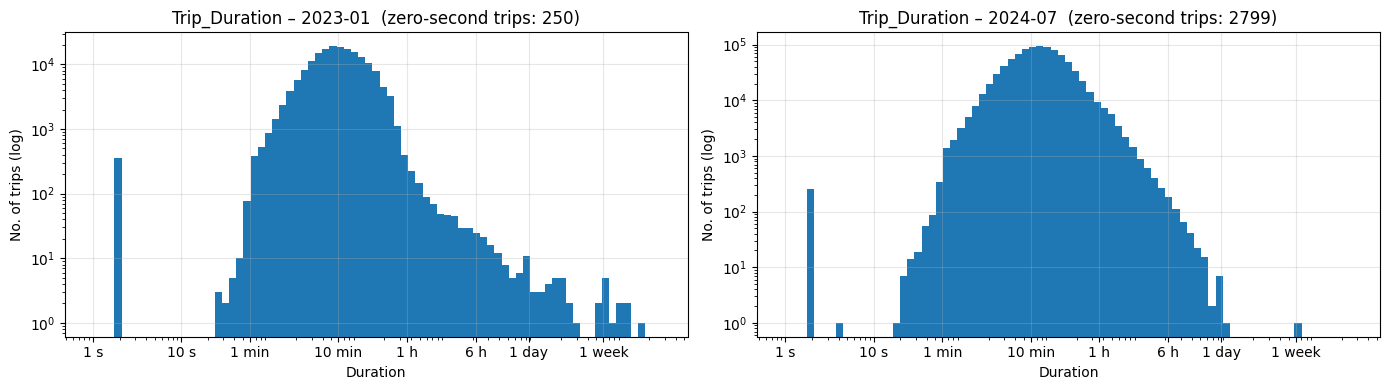

In [14]:
# Histogram with log-spaced bins (1 second to 30 days). Zero-second trips cannot be plotted on a log axis and are counted separately.
bins = np.logspace(0, np.log10(30 * 86400), 80)
ticks = [1, 10, 60, 600, 3600, 6*3600, 86400, 7*86400]
tick_labels = ["1 s", "10 s", "1 min", "10 min", "1 h", "6 h", "1 day", "1 week"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name in zip(axes, ["2023-01", "2024-07"]):
    d = samples[name]["Trip_Duration"]
    ax.hist(d[d > 0], bins=bins)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xticks(ticks); ax.set_xticklabels(tick_labels)
    ax.set_title(f"Trip_Duration – {name}  (zero-second trips: {(d == 0).sum()})")
    ax.set_xlabel("Duration"); ax.set_ylabel("No. of trips (log)")
    ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

**OBSERVATIONS:**
- There is a tall spike at the far left (trips of 1 to 3 seconds). These are the invalid trips (dock re-locking). After that, there are almost no trips between 3 seconds and about 1 minute. Then the main graph of real rides rising from about 1 minute and peaking around 10 minutes.
- On the right side of the graph, the number of trips curve downward from about 30 minutes to a few hours. Then, we see scattered bars from around 1 day and beyond. This is the upper side of outliers/invalid trips that cannot be real rides. These may be bikes that were not returned (or returned without being docked properly).
- The gap on the left between 3 s and 1 min is where we can put the threshold for a short-trip cutoff.
- On the upper limit (long-trip cutoff), we should check other months or the full Trip Duration dataset.

### 2.3 Candidate cutoffs: how many trips are very short or very long?

To decide the threshold for too-short and too-long trips, we will count how many trips fall below several short cutoffs and above several long cutoffs.

In [15]:
# Count and % of trips shorter than / longer than each candidate cutoff, for the sample months
short_cuts = {"< 3 s": 3, "< 10 s": 10, "< 30 s": 30, "< 1 min": 60, "< 2 min": 120}
long_cuts  = {"> 1 h": 3600, "> 2 h": 7200, "> 3 h": 10800, "> 6 h": 21600, "> 12 h": 43200, "> 1 day": 86400, "> 1 week": 604800}

rows = []
for name, df in samples.items():
    d = df["Trip_Duration"]; n = len(d)
    r = {"month": name, "trips": n}
    for label, cut in short_cuts.items():
        r[label] = f"{(d < cut).sum():,} ({(d < cut).mean()*100:.2f}%)"
    for label, cut in long_cuts.items():
        r[label] = f"{(d > cut).sum():,} ({(d > cut).mean()*100:.3f}%)"
    rows.append(r)
pd.DataFrame(rows).set_index("month").T

month,2023-01,2024-01,2024-07,2025-01,2026-01
trips,180135,204879,906372,202946,137336
< 3 s,601 (0.33%),403 (0.20%),"3,052 (0.34%)",397 (0.20%),"1,169 (0.85%)"
< 10 s,601 (0.33%),403 (0.20%),"3,053 (0.34%)",398 (0.20%),"1,169 (0.85%)"
< 30 s,604 (0.34%),406 (0.20%),"3,077 (0.34%)",401 (0.20%),"1,172 (0.85%)"
< 1 min,666 (0.37%),475 (0.23%),"3,424 (0.38%)",512 (0.25%),"1,213 (0.88%)"
< 2 min,"3,168 (1.76%)","3,304 (1.61%)","12,597 (1.39%)","3,372 (1.66%)","2,636 (1.92%)"
> 1 h,924 (0.513%),"1,921 (0.938%)","24,263 (2.677%)",527 (0.260%),397 (0.289%)
> 2 h,369 (0.205%),385 (0.188%),"5,042 (0.556%)",134 (0.066%),116 (0.084%)
> 3 h,257 (0.143%),255 (0.124%),"1,977 (0.218%)",87 (0.043%),60 (0.044%)
> 6 h,131 (0.073%),165 (0.081%),381 (0.042%),45 (0.022%),42 (0.031%)


**OBSERVATIONS:**
- Short side: the count under 3 s and the count under 1 min are almost the same (ex. 601 vs 666 in Jan 2023). Nearly all trips that are shorter than 1 minute are only a few seconds long. Between 1 and 2 minutes the count jumps to 1.4 to 1.9% of trips which may indicate that these are real short rides (ex. riding for very short distances or a couple of streets).
- Long side: trips over 1 hour are 0.3% of a winter month but 2.7% of July 2024. This is not unusual because riders are more likely to ride long distances for leisure or tourism in warmer months. For over 3 hours the share is 0.04 to 0.22%. Trips that are over 1 day are at most 0.03%.
- The percentage of very short trips is higher in January 2026 (0.85%) than in the other months (0.2 to 0.4%).

### 2.4 Trips that start and end at the same station

A trip that starts and ends at the same station can be real (a round trip) or a dock re-lock (someone took a bike out, found a problem and put it straight back). We can use the trip duration to check this.

In [16]:
# Same-station trips and their durations
for name, df in samples.items():
    same = df[df["Start_Station_Id"] == df["End_Station_Id"]]
    print(f"\n{name}: same-station trips = {len(same):,} ({len(same)/len(df)*100:.1f}% of trips)")
    print("   of which under 1 min:", (same["Trip_Duration"] < 60).sum(),
          " | under 2 min:", (same["Trip_Duration"] < 120).sum(),
          " | median duration:", human(same["Trip_Duration"].median()))


2023-01: same-station trips = 4,620 (2.6% of trips)
   of which under 1 min: 34  | under 2 min: 870  | median duration: 13.4 min

2024-01: same-station trips = 4,464 (2.2% of trips)
   of which under 1 min: 47  | under 2 min: 751  | median duration: 14.5 min

2024-07: same-station trips = 29,213 (3.2% of trips)
   of which under 1 min: 148  | under 2 min: 2876  | median duration: 24.9 min

2025-01: same-station trips = 2,990 (1.5% of trips)
   of which under 1 min: 26  | under 2 min: 732  | median duration: 10.4 min

2026-01: same-station trips = 1,823 (1.3% of trips)
   of which under 1 min: 53  | under 2 min: 465  | median duration: 9.6 min


**OBSERVATION:** 1.3 to 3.2% of trips return to the station they started from, and their median duration is 10 to 25 minutes, so most are actual round trips. A few dozen per month (26 to 148) are under 1 minute; those are already covered by the short-trip cutoff above, so no separate same-station rule is needed.

### 2.5 Time consistency: does End_Time minus Start_Time match Trip_Duration?

In [17]:
# Compare the duration implied by the timestamps with the Trip_Duration column
for name, df in samples.items():
    implied = (df["End_Time"] - df["Start_Time"]).dt.total_seconds()
    diff = (implied - df["Trip_Duration"]).abs()
    print(f"\n{name}:")
    print("   End_Time before Start_Time:     ", (implied < 0).sum())
    print("   |implied - Trip_Duration| > 60 s:", (diff > 60).sum(), f"({(diff > 60).mean()*100:.3f}%)")
    print("   rows where End_Time is missing:  ", df["End_Time"].isna().sum())
    print("   zero-second trips:               ", (df["Trip_Duration"] == 0).sum())


2023-01:
   End_Time before Start_Time:      0
   |implied - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   0
   zero-second trips:                250

2024-01:
   End_Time before Start_Time:      0
   |implied - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   4
   zero-second trips:                183

2024-07:
   End_Time before Start_Time:      0
   |implied - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   2170
   zero-second trips:                2799

2025-01:
   End_Time before Start_Time:      0
   |implied - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   26
   zero-second trips:                166

2026-01:
   End_Time before Start_Time:      0
   |implied - Trip_Duration| > 60 s: 0 (0.000%)
   rows where End_Time is missing:   42
   zero-second trips:                347


In [18]:
# The rows with a missing End_Time: what does Trip_Duration look like for them?
df = samples["2024-07"]
no_end_time = df["End_Time"].isna()
print("Rows with missing End_Time:", no_end_time.sum())
print("Their Trip_Duration values:", df.loc[no_end_time, "Trip_Duration"].value_counts().to_dict())
print("Of these, also missing End_Station_Id:", (no_end_time & df["End_Station_Id"].isna()).sum())

Rows with missing End_Time: 2170
Their Trip_Duration values: {0: 2170}
Of these, also missing End_Station_Id: 928


**OBSERVATIONS:**
- The timestamps and `Trip_Duration` agree in every sample month (0 rows differ by more than 60 s) and no trip ends before it starts.
- Every row with a missing `End_Time` has a `Trip_Duration` of **0 seconds**: these are incomplete trip records (the trip never properly ended), not real rides. They will be caught by the short-trip rule, so no separate rule is needed.
- Zero-second trips: 166 to 2,799 per sample month (0.1 to 0.3%).

### 2.6 Station ids and names

In [19]:
# How many distinct stations, and do any station ids have more than one name inside the same month?
for name, df in samples.items():
    n_start = df["Start_Station_Id"].nunique()
    names_per_id = df.groupby("Start_Station_Id")["Start_Station_Name"].nunique()
    print(f"{name}: distinct start stations = {n_start:,}  | ids with more than one name in the month = {(names_per_id > 1).sum()}"
          f"  | rows with a missing Start_Station_Name = {df['Start_Station_Name'].isna().sum():,}")

2023-01: distinct start stations = 651  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 10,630
2024-01: distinct start stations = 773  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 0
2024-07: distinct start stations = 826  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 0
2025-01: distinct start stations = 848  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 0
2026-01: distinct start stations = 918  | ids with more than one name in the month = 0  | rows with a missing Start_Station_Name = 0


In [ ]:
# Duplicate Trip_Id, and near-duplicates (same bike, same start time, different Trip_Id)
for name, df in samples.items():
    dup_id = df["Trip_Id"].duplicated().sum()
    near = df.duplicated(subset=["Bike_Id", "Start_Time"]).sum()
    print(f"{name}: duplicate Trip_Id = {dup_id}  | same Bike_Id + Start_Time = {near}")

2023-01: duplicate Trip_Id = 0  | same Bike_Id + Start_Time = 0
2024-01: duplicate Trip_Id = 0  | same Bike_Id + Start_Time = 0


2024-07: duplicate Trip_Id = 0  | same Bike_Id + Start_Time = 28
2025-01: duplicate Trip_Id = 0  | same Bike_Id + Start_Time = 0
2026-01: duplicate Trip_Id = 0  | same Bike_Id + Start_Time = 9


**OBSERVATIONS:**
- The number of distinct start stations grows from 651 (Jan 2023) to 918 (Jan 2026). This is part of the growth plan of Bike Share Toronto. Station IDs that appear in later years only are the new stations that were added.
- No station id has two different names inside a month. The 10,630 missing `Start_Station_Name` values in Jan 2023 are missing names only. the ids are present, so trips can still be counted per station. We can just use Station IDs and remove Station Names as a feature.
- No duplicate `Trip_Id` in any sample month. A few rows share the same bike and the same start time (28 in Jul 2024).

## 3. Profiling All 39 Months

We will run the same checks over every month to compare the findings from the sample months to the rest of the dataset. The loop reads one file at a time (so it fits in memory), computes a small set of numbers for that month, and throws the month away. The results are saved to `data/profile/` so that they can be reused in EDA.

Note on this section: Created with the help of AI to help profile the full dataset based on the initial findings on the yearly sample files.

### 3.1 Helper functions

In [20]:
def load_raw_month(path):
    """Read one monthly file, standardize the column names and parse the dates. No rows are removed."""
    df = pd.read_csv(path, low_memory=False)
    df = standardize_columns(df)
    df = parse_times(df)
    return df

def profile_month(df, year, month):
    """Compute the checks from Sections 1 and 2 for one month and return them as a dictionary (one row of the profile table)."""
    d = df["Trip_Duration"]
    implied = (df["End_Time"] - df["Start_Time"]).dt.total_seconds()
    month_start = pd.Timestamp(year=year, month=month, day=1)
    month_end = month_start + pd.offsets.MonthBegin(1)

    row = {"year": year, "month": month, "rows": len(df),
           "duplicate_trip_id": int(df["Trip_Id"].duplicated().sum()),
           "same_bike_same_start": int(df.duplicated(subset=["Bike_Id", "Start_Time"]).sum()),
           "start_time_unparsed": int(df["Start_Time"].isna().sum()),
           "start_outside_month": int(((df["Start_Time"] < month_start) | (df["Start_Time"] >= month_end)).sum()),
           "end_before_start": int((implied < 0).sum()),
           "time_mismatch_gt60s": int(((implied - d).abs() > 60).sum()),
           "zero_duration": int((d == 0).sum()),
           "same_station": int((df["Start_Station_Id"] == df["End_Station_Id"]).sum()),
           "same_station_lt60s": int(((df["Start_Station_Id"] == df["End_Station_Id"]) & (d < 60)).sum()),
           "n_start_stations": int(df["Start_Station_Id"].nunique()),
           "n_end_stations": int(df["End_Station_Id"].nunique()),
           "n_bikes": int(df["Bike_Id"].nunique()),
           "casual": int((df["User_Type"].isin(["Casual", "Casual Member"])).sum()),
           "member": int((df["User_Type"].isin(["Member", "Annual Member"])).sum()),
           "ebike": int(df["Bike_Model"].isin(["EFIT", "EFIT G5", "ASTRO"]).sum()),
           }
    for col in STANDARD_COLUMNS:                                  # missing values per column
        row[f"miss_{col}"] = int(df[col].isna().sum())
    for label, cut in short_cuts.items():                          # candidate short cutoffs
        row[f"lt_{cut}s"] = int((d < cut).sum())
    for label, cut in long_cuts.items():                           # candidate long cutoffs
        row[f"gt_{cut}s"] = int((d > cut).sum())
    for p in [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]:
        row[f"dur_p{p*100:g}"] = float(d.quantile(p))
    row["dur_min"] = int(d.min()); row["dur_max"] = int(d.max()); row["dur_mean"] = float(d.mean())
    return row

### 3.2 Run the loop over every monthly file

In [23]:
PROFILE_FILE = f"{PROFILE}/profile_by_month.csv"
STATION_FILE = f"{PROFILE}/station_months.csv"       # one row per station per month: used later for the station first-seen table
HIST_FILE    = f"{PROFILE}/tripdur_hist.npy"        # histogram counts of Trip_Duration: row 0 = training years 2023-2024, row 1 = test years 2025-2026

TRAIN_YEARS = [2023, 2024]        # the project's training years; 2025 is the test year and 2026 Q1 the final check

if os.path.exists(PROFILE_FILE) and os.path.exists(STATION_FILE) and os.path.exists(HIST_FILE):
    profile = pd.read_csv(PROFILE_FILE)
    station_months = pd.read_csv(STATION_FILE)
    hist_train, hist_test = np.load(HIST_FILE)
    print("Loaded the saved profile:", profile.shape)
else:
    profile_rows, station_rows = [], []
    hist_train, hist_test = np.zeros(len(bins) - 1), np.zeros(len(bins) - 1)
    for _, f in file_table.iterrows():
        path = f"{RAW}/{f['year']}/{f['file']}"
        df = load_raw_month(path)
        profile_rows.append(profile_month(df, f["year"], f["month"]))
        # station x month counts (start stations), with the most common name for the id that month
        sm = (df.groupby("Start_Station_Id")
                .agg(trips=("Trip_Id", "size"), name=("Start_Station_Name", lambda s: s.mode().iloc[0] if s.notna().any() else np.nan))
                .reset_index())
        sm["year"], sm["month"] = f["year"], f["month"]
        station_rows.append(sm)
        d = df["Trip_Duration"]
        h = np.histogram(d[d > 0], bins=bins)[0]
        if f["year"] in TRAIN_YEARS:
            hist_train += h
        else:
            hist_test += h
        print(f"{f['year']}-{f['month']:02d}: {len(df):>9,} rows   done")
    profile = pd.DataFrame(profile_rows)
    station_months = pd.concat(station_rows, ignore_index=True)
    profile.to_csv(PROFILE_FILE, index=False)
    station_months.to_csv(STATION_FILE, index=False)
    np.save(HIST_FILE, np.vstack([hist_train, hist_test]))
    print("Saved:", PROFILE_FILE)

profile["year_month"] = profile["year"].astype(str) + "-" + profile["month"].astype(str).str.zfill(2)
profile["split"] = np.where(profile["year"].isin(TRAIN_YEARS), "train 2023-24", "test 2025-26")
TOTAL_ROWS = profile["rows"].sum()
TOTAL_TRAIN = profile.loc[profile["split"] == "train 2023-24", "rows"].sum()
TOTAL_TEST = TOTAL_ROWS - TOTAL_TRAIN
print("Total trips in all 39 files:", f"{TOTAL_ROWS:,}", f"  (training years {TOTAL_TRAIN:,}, test years {TOTAL_TEST:,})")

2023-01:   180,135 rows   done
2023-02:   172,776 rows   done
2023-03:   224,545 rows   done
2023-04:   380,346 rows   done
2023-05:   589,217 rows   done
2023-06:   663,691 rows   done
2023-07:   735,924 rows   done
2023-08:   760,141 rows   done
2023-09:   754,303 rows   done
2023-10:   601,075 rows   done
2023-11:   393,873 rows   done
2023-12:   257,115 rows   done
2024-01:   204,879 rows   done
2024-02:   261,774 rows   done
2024-03:   312,613 rows   done
2024-04:   403,788 rows   done
2024-05:   686,392 rows   done
2024-06:   766,868 rows   done
2024-07:   906,372 rows   done
2024-08:   907,154 rows   done
2024-09:   901,638 rows   done
2024-10:   794,021 rows   done
2024-11:   555,648 rows   done
2024-12:   251,947 rows   done
2025-01:   202,946 rows   done
2025-02:   125,670 rows   done
2025-03:   312,178 rows   done
2025-04:   471,525 rows   done
2025-05:   699,461 rows   done
2025-06:   980,624 rows   done
2025-07: 1,192,062 rows   done
2025-08: 1,164,697 rows   done
2025-09:

### 3.3 Totals by year

In [24]:
# Rows, duplicates and the consistency checks, summed per year
check_cols = ["rows", "duplicate_trip_id", "same_bike_same_start", "start_time_unparsed", "start_outside_month",
              "end_before_start", "time_mismatch_gt60s", "zero_duration", "same_station", "same_station_lt60s"]
by_year = profile.groupby("year")[check_cols].sum()
by_year.loc["TOTAL"] = by_year.sum()
by_year

,rows,duplicate_trip_id,same_bike_same_start,start_time_unparsed,start_outside_month,end_before_start,time_mismatch_gt60s,zero_duration,same_station,same_station_lt60s
year,,,,,,,,,,
2023,5713141,0,20,0,0,49,104,4396,183612,1004
2024,6953094,0,87,0,0,47,112,10873,187477,997
2025,7812520,0,143,0,0,176,266,5479,247238,2185
2026,552073,0,105,0,0,0,32,1535,8376,209
TOTAL,21030828,0,355,0,0,272,514,22283,626703,4395


In [25]:
# Missing values per column as a % of rows, per year
miss_cols = [c for c in profile.columns if c.startswith("miss_")]
miss_pct = profile.groupby("year")[miss_cols].sum().div(profile.groupby("year")["rows"].sum(), axis=0) * 100
miss_pct.columns = [c.replace("miss_", "") for c in miss_pct.columns]
miss_pct.round(3).T

year,2023,2024,2025,2026
Trip_Id,0.000,0.000,0.000,0.000
Trip_Duration,0.000,0.000,0.000,0.000
Start_Station_Id,0.000,0.000,0.000,0.000
Start_Time,0.000,0.000,0.000,0.000
Start_Station_Name,10.416,0.000,0.000,0.000
End_Station_Id,0.052,0.121,0.087,0.269
End_Time,0.000,0.084,0.014,0.090
End_Station_Name,10.477,0.121,0.012,0.269
Bike_Id,0.000,0.000,0.000,0.000
User_Type,0.000,0.000,0.000,0.000


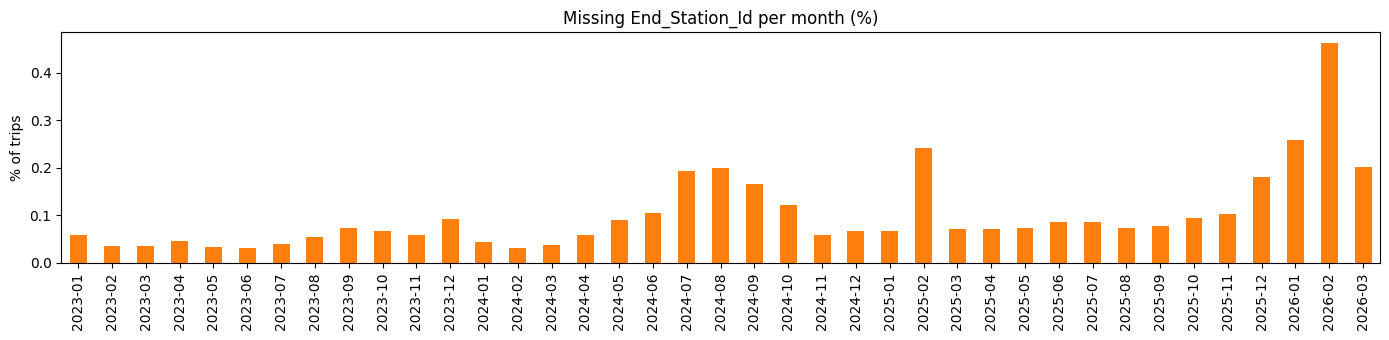

In [26]:
# Missing End_Station_Id per month, as a %
profile["miss_end_pct"] = profile["miss_End_Station_Id"] / profile["rows"] * 100
ax = profile.plot(x="year_month", y="miss_end_pct", kind="bar", figsize=(14, 3.5), legend=False, color="tab:orange")
ax.set_ylabel("% of trips"); ax.set_xlabel(""); ax.set_title("Missing End_Station_Id per month (%)")
plt.tight_layout(); plt.show()

**OBSERVATIONS:**
- The 39 files include **21,030,828 trips**. There is no duplicate `Trip_Id` in any month. Only 355 rows (0.002%) share a bike and a start time.
- `end_before_start` (272 rows) occured in November (2023: 49, 2024: 47, 2025: 176), and `time_mismatch_gt60s` (514 rows) are in March and November. Those may be due to daylight-saving clock changes. The timestamps are off by one hour but `Trip_Duration` shows the actual length of the trips. These are real trips, so we shouldn't just remove them as errors. **Note to the group: Consider the daylight saving clock changes when analyzing the departures and arrivals in these months.**
- There are ver few missing values except for two columns: `Start_Station_Name` is missing in 10.4% of 2023 rows (names only; ids are complete) and `Bike_Model` does not exist in 2023. `End_Station_Id` is missing in 0.05 to 0.27% of rows per year and peaks in the summer of 2024 (bar chart). `End_Time` is missing in 0.01 to 0.09% of rows from 2024, always together with a zero duration (2.5).

- We won't be using `Bike_Model` since it doesn't exist in 2023 and we cannot form an analysis on this given our training dataset.

### 3.4 Volume: trips per month, user type share, stations per month

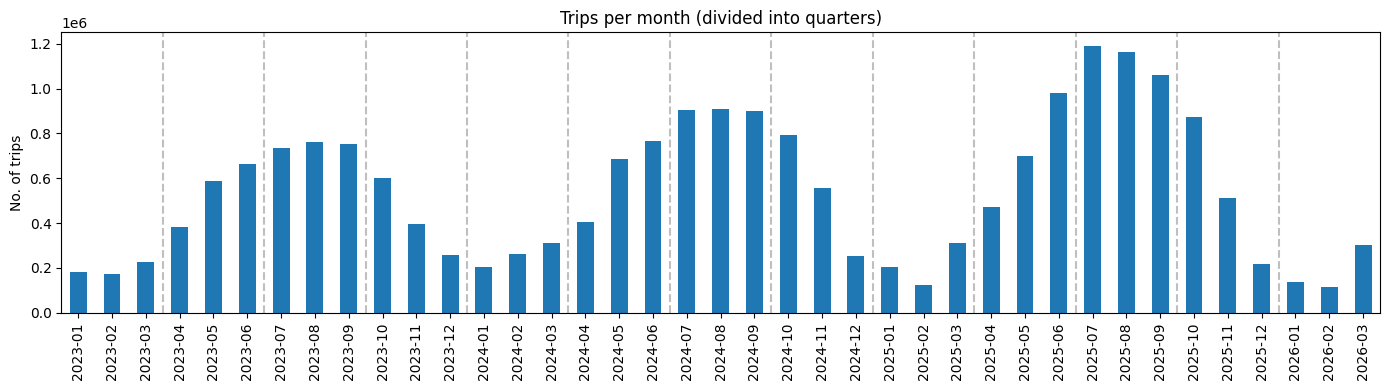

In [29]:
# Trips per month across all years.
ax = profile.plot(x="year_month", y="rows", kind="bar", figsize=(14, 4), legend=False)
for i, ym in enumerate(profile["year_month"]):
    if ym.endswith(("-01", "-04", "-07", "-10")):
        ax.axvline(i - 0.5, color="grey", linestyle="--", alpha=0.5)
ax.set_ylabel("No. of trips"); ax.set_xlabel(""); ax.set_title("Trips per month (divided into quarters)")
plt.tight_layout(); plt.show()

In [30]:
# Trips per year and per quarter
profile["quarter"] = "Q" + ((profile["month"] - 1) // 3 + 1).astype(str)
print("Trips per year:")
print(profile.groupby("year")["rows"].sum().map("{:,}".format))
print("\nTrips per quarter (all years):")
print(profile.groupby("quarter")["rows"].sum().map("{:,}".format))

Trips per year:
year
2023    5,713,141
2024    6,953,094
2025    7,812,520
2026      552,073
Name: rows, dtype: object

Trips per quarter (all years):
quarter
Q1    2,549,589
Q2    5,641,912
Q3    8,384,292
Q4    4,455,035
Name: rows, dtype: object


In [31]:
# Casual vs member share and e-bike share per year
share = profile.groupby("year")[["rows", "casual", "member", "ebike"]].sum()
share["casual_%"] = (share["casual"] / share["rows"] * 100).round(1)
share["ebike_%"]  = (share["ebike"]  / share["rows"] * 100).round(1)
share

,rows,casual,member,ebike,casual_%,ebike_%
year,,,,,,
2023,5713141,5348784,364357,0,93.6,0.0
2024,6953094,1586909,5366185,1073937,22.8,15.4
2025,7812520,2141436,5671084,1513762,27.4,19.4
2026,552073,61170,490903,30234,11.1,5.5


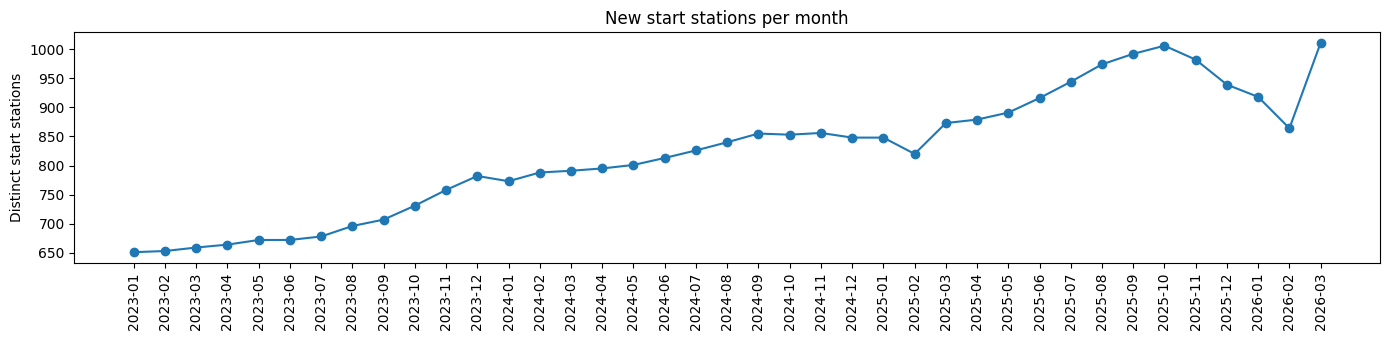

In [33]:
# New start stations per month (station network growth)
ax = profile.plot(x="year_month", y="n_start_stations", kind="line", marker="o", figsize=(14, 3.5), legend=False)
ax.set_ylabel("Distinct start stations"); ax.set_xlabel(""); ax.set_title("New start stations per month")
ax.set_xticks(range(len(profile))); ax.set_xticklabels(profile["year_month"], rotation=90)
plt.tight_layout(); plt.show()

In [34]:
# Recheck the 2023 user type counts
profile[profile["year"] == 2023][["year_month", "rows", "casual", "member"]].assign(
    casual_pct=lambda t: (t["casual"] / t["rows"] * 100).round(1)).set_index("year_month").T

year_month,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12
rows,180135.0,172776.0,224545.0,380346.0,589217.0,663691.0,735924.0,760141.0,754303.0,601075.0,393873.0,257115.0
casual,130135.0,130015.0,173584.0,303161.0,506640.0,615182.0,723698.0,760003.0,754303.0,601075.0,393873.0,257115.0
member,50000.0,42761.0,50961.0,77185.0,82577.0,48509.0,12226.0,138.0,0.0,0.0,0.0,0.0
casual_pct,72.2,75.3,77.3,79.7,86.0,92.7,98.3,100.0,100.0,100.0,100.0,100.0


**OBSERVATIONS:**
- Volume: 5.71 M trips in 2023, 6.95 M in 2024. The data also shows that trips continued to grow in 2025 and the first quarter of 2026.
- We can see a pattern of seasonal riders. The rides in Q3 (Jul-Sept) are highest and Q1 (Jan-Mar) are the lowest.
- The 2023 `User_Type` column seems to have incorrect data. For 2023, 93.6% of trips were marked as casual and annual member count in September is 0. But in 2024 onwards, there are only ~23%+ of casual trips. We will not be analyzing user types in our project.
- Stations: the number of active start stations rises steadily from 651 to 1,011. New stations will need to be flagged so that "growth" at a station that just opened is not confused with growing demand.

### 3.5 Trip_Duration: choosing the cutoffs from the training years

Note: (possible data leakage?) The checks so far (schema, types, missing values, duplicates) had to run on every month, because the test data must be loaded and cleaned with the same code as the training data. The *cutoffs* below are a decision, so they are chosen from the training years 2023–2024 only. The test years 2025–2026 are shown next to them only to confirm that the rule still behaves the same there, not to pick the rule.

In [35]:
# Percentiles per year (seconds), using the median of the monthly values as a summary
pcols = ["dur_min", "dur_p0.1", "dur_p1", "dur_p5", "dur_p50", "dur_p95", "dur_p99", "dur_p99.9", "dur_max"]
profile.groupby("year")[pcols].median().map(human)

,dur_min,dur_p0.1,dur_p1,dur_p5,dur_p50,dur_p95,dur_p99,dur_p99.9,dur_max
year,,,,,,,,,
2023,0 s,2 s,1.8 min,3.2 min,11.0 min,38.2 min,1.4 h,6.0 h,28.4 days
2024,0 s,1 s,1.8 min,3.2 min,10.7 min,35.2 min,1.2 h,4.1 h,11.6 days
2025,0 s,2 s,1.8 min,3.2 min,10.7 min,35.3 min,1.3 h,3.5 h,1.0 days
2026,0 s,0 s,1.2 min,3.0 min,9.7 min,27.5 min,42.8 min,2.2 h,1.0 days


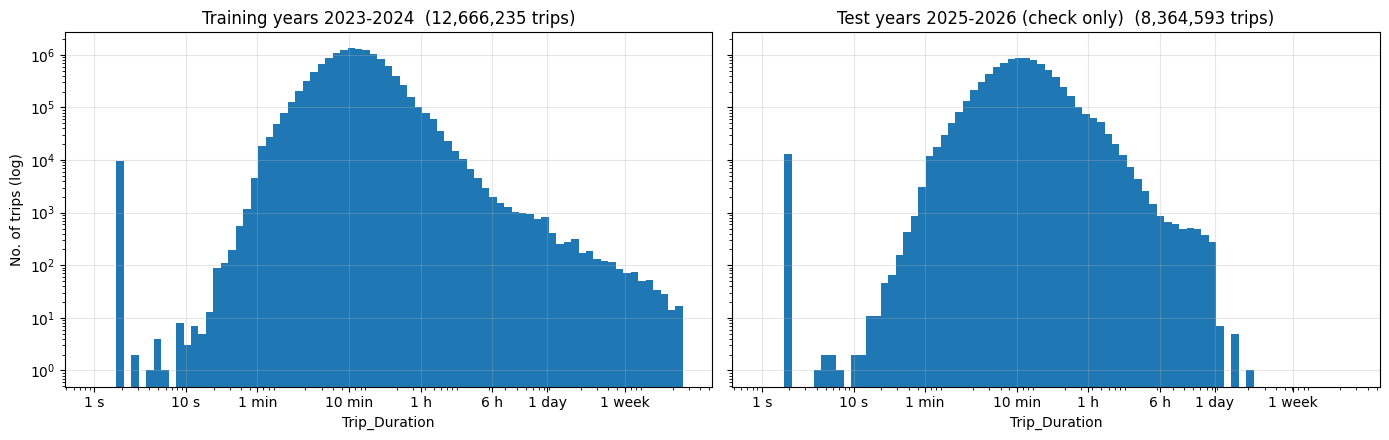

Zero-second trips (not on the log axis): training 15,269  test 7,014


In [36]:
# Histogram of Trip_Duration (log-log): training years on the left, test years on the right for comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, h, title, n in [(axes[0], hist_train, "Training years 2023-2024", TOTAL_TRAIN), (axes[1], hist_test, "Test years 2025-2026 (check only)", TOTAL_TEST)]:
    ax.bar(bins[:-1], h, width=np.diff(bins), align="edge")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xticks(ticks); ax.set_xticklabels(tick_labels)
    ax.set_xlabel("Trip_Duration"); ax.set_title(f"{title}  ({n:,} trips)")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("No. of trips (log)")
plt.tight_layout(); plt.show()
print("Zero-second trips (not on the log axis): training", f"{profile.loc[profile['split']=='train 2023-24','zero_duration'].sum():,}",
      " test", f"{profile.loc[profile['split']=='test 2025-26','zero_duration'].sum():,}")

In [37]:
# Candidate cutoffs: count and % of trips, training years (used for the decision) and test years (check only)
tr = profile[profile["split"] == "train 2023-24"]; te = profile[profile["split"] == "test 2025-26"]
cut_table = []
for label, cut in list(short_cuts.items()) + list(long_cuts.items()):
    col = f"lt_{cut}s" if label.startswith("<") else f"gt_{cut}s"
    cut_table.append({"cutoff": label,
                      "trips 2023-24": tr[col].sum(), "% 2023-24": round(tr[col].sum() / TOTAL_TRAIN * 100, 3),
                      "trips 2025-26": te[col].sum(), "% 2025-26": round(te[col].sum() / TOTAL_TEST * 100, 3)})
cut_table = pd.DataFrame(cut_table).set_index("cutoff")
cut_table

,trips 2023-24,% 2023-24,trips 2025-26,% 2025-26
cutoff,,,,
< 3 s,24928,0.197,19880,0.238
< 10 s,24944,0.197,19886,0.238
< 30 s,25194,0.199,20047,0.240
< 1 min,29813,0.235,23396,0.280
< 2 min,164883,1.302,108759,1.300
> 1 h,266657,2.105,214439,2.564
> 2 h,60989,0.482,40732,0.487
> 3 h,28662,0.226,14557,0.174
> 6 h,10885,0.086,3946,0.047


In [40]:
# Check the training years to find the upper limit threshold.
tail = pd.DataFrame({"from": bins[:-1], "to": bins[1:], "trips": hist_train.astype(int)})
tail = tail[tail["from"] >= 3600].copy()
tail["from"] = tail["from"].map(human); tail["to"] = tail["to"].map(human)
tail["change vs previous bin"] = (tail["trips"] / tail["trips"].shift(1)).round(2)
tail.set_index("from").head(22)

,to,trips,change vs previous bin
from,,,
1.0 h,1.3 h,79318,NaN
1.3 h,1.5 h,60889,0.77
1.5 h,1.8 h,35113,0.58
1.8 h,2.2 h,22581,0.64
2.2 h,2.6 h,15004,0.66
2.6 h,3.2 h,10302,0.69
3.2 h,3.8 h,6664,0.65
3.8 h,4.6 h,4523,0.68
4.6 h,5.6 h,3003,0.66


**OBSERVATIONS:**
- The histograms are similar across years, so we can use the same thresholds for all years.
- The training-years histogram has the same shape as the sample months, and the test-years histogram looks the same.

**Short trips cutoff**
- In 2023–2024 (12.7 M trips):
  - Less than 3 seconds: 24,928 trips
  - 3 seconds to 1 minute: 4,885
  - 1-2 minutes: 135,000
- A 1-minute cutoff flags 0.235% of training trips. A 2-minute cutoff would flag 1.3% but would start removing real rides.

**Long trips cutoff**
- On the long-trips side, each bin in the table above shows that there a 60-70% change compared to the previous bit from ~1 hour to 6.7 hours, then plateaus until around 1 day (see the histogram).
- In 2023-2024:
  - more than 3 hours: 28,662 (0.23%)
  - more than 6 hours: 10,885 (0.09%)
  - more than 1 day: 2,599 (0.02%)

- We can choose either 3 hours or 6 hours as our upper threshold/cutoff since the percentage is very small, but to keep more real rides, we will choose the 6 hours.

## 4. Findings and Proposed Cleaning Rules

In [41]:
# The key numbers behind the findings, computed from the profile table.
# Cutoff decisions (R1, R2) use the training years; the test-years value is printed as a check.
n = TOTAL_ROWS
def both(col):
    a, b = tr[col].sum(), te[col].sum()
    return f"{a:,}  ({a/TOTAL_TRAIN*100:.3f}% of 2023-24)   | test years: {b:,} ({b/TOTAL_TEST*100:.3f}%)"
print(f"Total trips                           : {n:,}   (training years {TOTAL_TRAIN:,}, test years {TOTAL_TEST:,})")
print(f"Duplicate Trip_Id                     : {profile['duplicate_trip_id'].sum():,}")
print(f"Trips under 1 min (R1)                : {both('lt_60s')}")
print(f"   of which under 3 s                 : {both('lt_3s')}")
print(f"Trips over 3 h (R2 proposed)          : {both('gt_10800s')}")
print(f"Trips over 6 h (R2 alternative)       : {both('gt_21600s')}")
print(f"Missing End_Station_Id (R3)           : {profile['miss_End_Station_Id'].sum():,}  ({profile['miss_End_Station_Id'].sum()/n*100:.3f}%)")
print(f"Missing End_Time (zero-duration rows)  : {profile['miss_End_Time'].sum():,}  ({profile['miss_End_Time'].sum()/n*100:.3f}%)")
print(f"End before start + time mismatch (R5) : {profile['end_before_start'].sum():,} + {profile['time_mismatch_gt60s'].sum():,}  ({(profile['end_before_start'].sum()+profile['time_mismatch_gt60s'].sum())/n*100:.4f}%)")
print(f"Missing Start_Station_Name, 2023 only : {profile.loc[profile.year==2023,'miss_Start_Station_Name'].sum():,}  ({profile.loc[profile.year==2023,'miss_Start_Station_Name'].sum()/profile.loc[profile.year==2023,'rows'].sum()*100:.1f}% of 2023 rows)")

Total trips                           : 21,030,828   (training years 12,666,235, test years 8,364,593)
Duplicate Trip_Id                     : 0
Trips under 1 min (R1)                : 29,813  (0.235% of 2023-24)   | test years: 23,396 (0.280%)
   of which under 3 s                 : 24,928  (0.197% of 2023-24)   | test years: 19,880 (0.238%)
Trips over 3 h (R2 proposed)          : 28,662  (0.226% of 2023-24)   | test years: 14,557 (0.174%)
Trips over 6 h (R2 alternative)       : 10,885  (0.086% of 2023-24)   | test years: 3,946 (0.047%)
Missing End_Station_Id (R3)           : 19,612  (0.093%)
Missing End_Time (zero-duration rows)  : 7,412  (0.035%)
End before start + time mismatch (R5) : 272 + 514  (0.0037%)
Missing Start_Station_Name, 2023 only : 595,075  (10.4% of 2023 rows)
